# 🛒 03 · Canasta de compras (reglas de asociación)
Buscamos productos que se compran juntos en una misma factura, para armar **combos, promociones y recomendaciones**.

**Métricas:**
* **Support:** % de facturas que contienen ambos productos.
* **Confidence:** si compran A, probabilidad de que también compren B.
* **Lift:** cuántas veces más probable es comprar B teniendo A que comprarlo al azar (>1 = hay relación).

### Contenido
1. Preparación de las canastas
2. Algoritmo Apriori
3. Reglas de asociación
4. Visualización
5. Guardado de reglas

In [1]:
# Configuración general e importaciones
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "retail.db"
PROCESADOS = ROOT / "data" / "processed"
PROCESADOS.mkdir(parents=True, exist_ok=True)

PALETA = ["#6C5CE7", "#00CEC9", "#FD79A8", "#FDCB6E", "#74B9FF", "#55EFC4", "#E17055", "#A29BFE"]
COLOR_SEGMENTO = {
    "Campeones": "#FDCB6E", "Leales": "#00B894", "Nuevos / Prometedores": "#74B9FF",
    "Necesitan atención": "#A29BFE", "En Riesgo": "#E17055", "Perdidos / Hibernando": "#636E72",
}
px.defaults.template = "plotly_white"
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 1100
px.defaults.color_discrete_sequence = PALETA


def estilo(fig, titulo, alto=450):
    """Aplica el mismo formato visual a todos los gráficos del proyecto."""
    fig.update_layout(title=dict(text=f"<b>{titulo}</b>", x=0.01), height=alto,
                      font=dict(family="Segoe UI, Arial", size=13),
                      margin=dict(l=40, r=20, t=70, b=40), legend_title_text="")
    return fig


con = sqlite3.connect(DB)
print(f"Proyecto en: {ROOT}")

Proyecto en: C:\Users\eduar\retail-customer-segmentation-rfm


## 1 · Preparación de las canastas
Cada **factura** es una canasta. Se quitan las facturas de un solo producto (no aportan asociaciones) y se descartan los productos poco frecuentes, que no pueden superar el soporte mínimo.

In [2]:
# Parámetros del análisis
MIN_SUPPORT = 0.015
MIN_CONFIANZA = 0.30
MIN_LIFT = 3.0

In [3]:
# Carga de productos por factura con nombre único por código
lineas = pd.read_sql("SELECT Invoice, StockCode, Description FROM retail_sales_clean", con).dropna(subset=["Description"])
nombre = lineas.groupby("StockCode")["Description"].agg(lambda s: s.mode().iat[0]).str.strip()
lineas["Producto"] = lineas["StockCode"].map(nombre)

items = lineas[["Invoice", "Producto"]].drop_duplicates()
tamano = items.groupby("Invoice").size()
items = items[items["Invoice"].isin(tamano[tamano >= 2].index)]
facturas = items["Invoice"].unique()
print(f"Canastas (facturas con 2 o más productos): {len(facturas):,}")
print(f"Productos distintos: {items['Producto'].nunique():,}")

Canastas (facturas con 2 o más productos): 33,633
Productos distintos: 4,568


Matriz: 33,633 facturas × 382 productos frecuentes


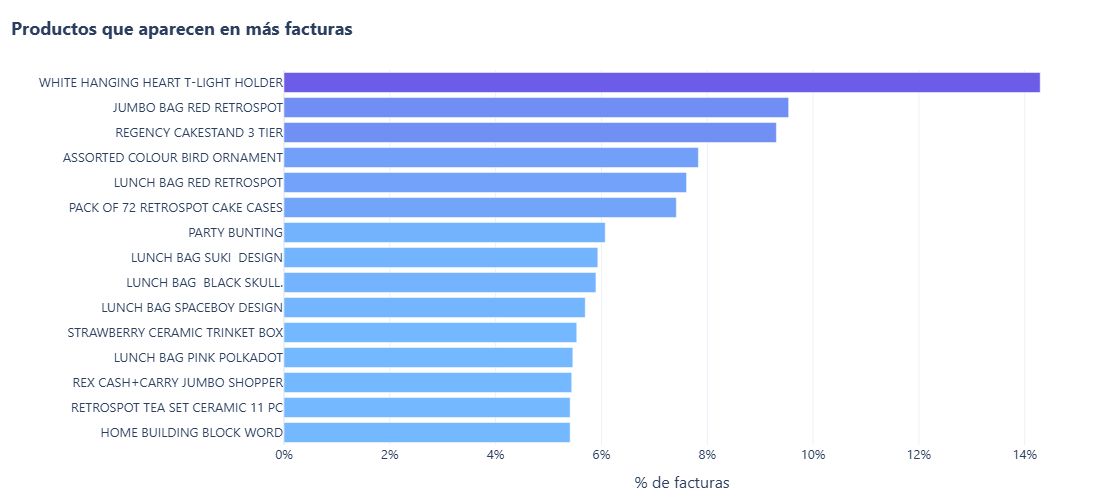

In [4]:
# Matriz de canastas (factura × producto) solo con productos frecuentes
frecuencia = items["Producto"].value_counts() / len(facturas)
frecuentes = frecuencia[frecuencia >= MIN_SUPPORT].index
sub = items[items["Producto"].isin(frecuentes)]
canastas = pd.crosstab(sub["Invoice"], sub["Producto"]).astype(bool).reindex(facturas, fill_value=False)
print(f"Matriz: {canastas.shape[0]:,} facturas × {canastas.shape[1]} productos frecuentes")

top = frecuencia.head(15).sort_values().reset_index()
top.columns = ["Producto", "% de facturas"]
fig = px.bar(top, x="% de facturas", y="Producto", orientation="h", color="% de facturas",
             color_continuous_scale=["#74B9FF", "#6C5CE7"])
fig.update_layout(coloraxis_showscale=False, xaxis_tickformat=".0%", yaxis_title="")
estilo(fig, "Productos que aparecen en más facturas", 500).show()

## 2 · Algoritmo Apriori
Encuentra los conjuntos de hasta 3 productos que aparecen juntos en al menos el soporte mínimo.

In [5]:
# Búsqueda de conjuntos frecuentes con Apriori
from mlxtend.frequent_patterns import apriori, association_rules

conjuntos = apriori(canastas, min_support=MIN_SUPPORT, use_colnames=True, max_len=3)
conjuntos["Tamaño"] = conjuntos["itemsets"].map(len)
print(f"Conjuntos frecuentes encontrados: {len(conjuntos):,}")
conjuntos["Tamaño"].value_counts().sort_index().rename("Cantidad").to_frame()

Conjuntos frecuentes encontrados: 484


,Cantidad
Tamaño,
1,382
2,97
3,5


## 3 · Reglas de asociación
Se conservan las reglas con lift y confianza altos.
Como `A → B` y `B → A` comparten el mismo lift, se marca **la dirección principal** (la de mayor confianza) para que el dashboard no muestre pares duplicados.

In [6]:
# Generación y limpieza de reglas
reglas = association_rules(conjuntos, metric="lift", min_threshold=MIN_LIFT)
reglas = reglas[reglas["confidence"] >= MIN_CONFIANZA].copy()

reglas["Par"] = reglas.apply(lambda f: frozenset(f["antecedents"] | f["consequents"]), axis=1)
reglas = reglas.sort_values(["confidence", "lift"], ascending=False)
reglas["Es_Direccion_Principal"] = ~reglas.duplicated("Par")
reglas["N_Items_Antecedente"] = reglas["antecedents"].map(len)
reglas["antecedents"] = reglas["antecedents"].map(lambda s: " + ".join(sorted(s)))
reglas["consequents"] = reglas["consequents"].map(lambda s: " + ".join(sorted(s)))
reglas = reglas.drop(columns="Par").sort_values("lift", ascending=False).reset_index(drop=True)

print(f"Reglas: {len(reglas)} · Pares únicos: {reglas['Es_Direccion_Principal'].sum()}")
reglas[reglas["Es_Direccion_Principal"]][["antecedents", "consequents", "support", "confidence", "lift"]].head(10)

Reglas: 169 · Pares únicos: 90


,antecedents,consequents,support,confidence,lift
2,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,GREEN REGENCY TEACUP AND SAUCER,0.02,0.89,32.14
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.02,0.84,30.26
9,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.02,0.80,25.48
11,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.02,0.79,25.31
12,TOILET METAL SIGN,BATHROOM METAL SIGN,0.02,0.77,24.28
14,BLUE 3 PIECE MINI DOTS CUTLERY SET,PINK 3 PIECE MINI DOTS CUTLERY SET,0.02,0.70,23.97
16,BLUE 3 PIECE MINI DOTS CUTLERY SET,RED 3 PIECE MINI DOTS CUTLERY SET,0.02,0.62,22.41
18,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.02,0.67,20.45
20,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.02,0.67,19.91
22,RED 3 PIECE MINI DOTS CUTLERY SET,PINK 3 PIECE MINI DOTS CUTLERY SET,0.02,0.55,18.71


## 4 · Visualización

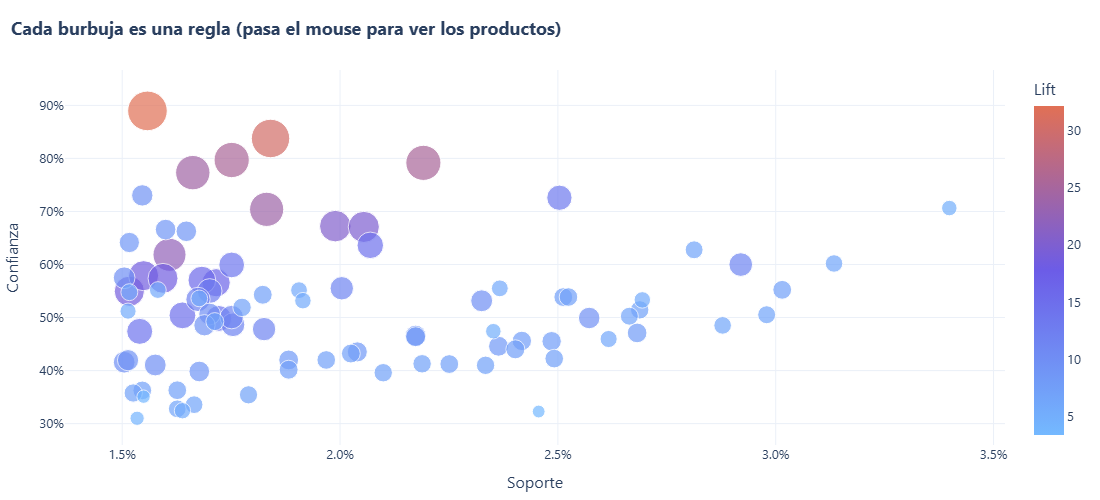

In [7]:
# Mapa de reglas: soporte vs confianza, tamaño y color por lift
principal = reglas[reglas["Es_Direccion_Principal"]].copy()
principal["Regla"] = principal["antecedents"] + "  →  " + principal["consequents"]
fig = px.scatter(principal, x="support", y="confidence", size="lift", color="lift", hover_name="Regla",
                 color_continuous_scale=["#74B9FF", "#6C5CE7", "#E17055"], size_max=28,
                 labels=dict(support="Soporte", confidence="Confianza", lift="Lift"))
fig.update_layout(xaxis_tickformat=".1%", yaxis_tickformat=".0%")
estilo(fig, "Cada burbuja es una regla (pasa el mouse para ver los productos)", 500).show()

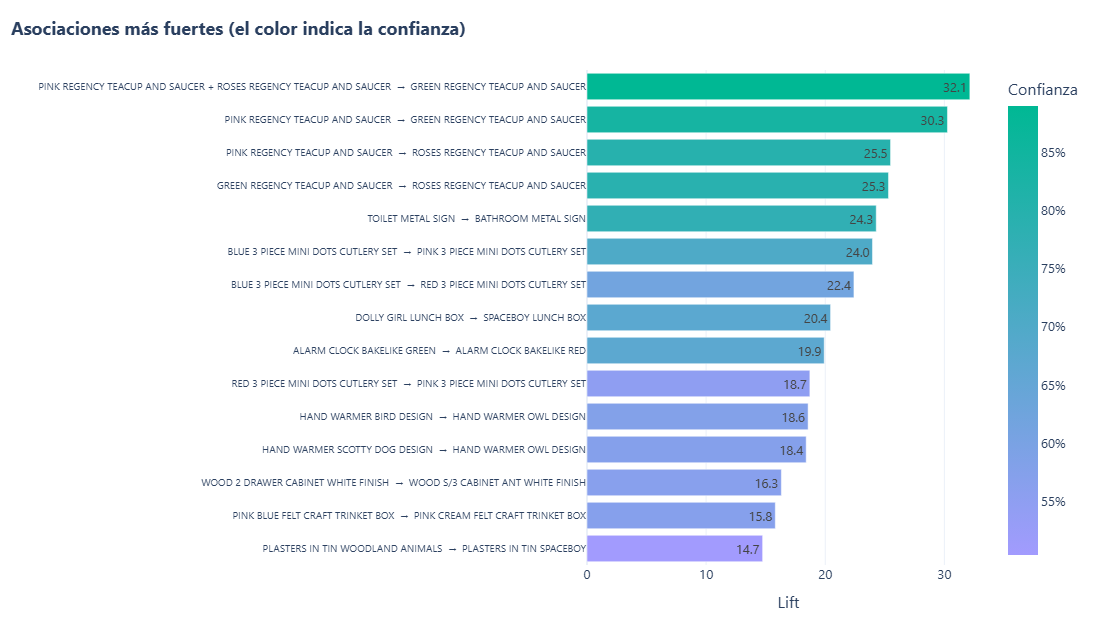

In [8]:
# Top 15 reglas por lift
top = principal.head(15).sort_values("lift")
fig = px.bar(top, x="lift", y="Regla", orientation="h", color="confidence", text=top["lift"].map("{:.1f}".format),
             color_continuous_scale=["#A29BFE", "#00B894"], labels=dict(confidence="Confianza", lift="Lift"))
fig.update_layout(yaxis_title="", yaxis_tickfont_size=10, coloraxis_colorbar_tickformat=".0%")
estilo(fig, "Asociaciones más fuertes (el color indica la confianza)", 620).show()

## 5 · Guardado de resultados

In [9]:
# Guardado de reglas en SQLite y CSV
columnas = ["antecedents", "consequents", "antecedent support", "consequent support", "support", "confidence",
            "lift", "leverage", "conviction", "Es_Direccion_Principal", "N_Items_Antecedente"]
reglas[columnas].to_sql("market_basket_rules", con, if_exists="replace", index=False)
reglas[columnas].to_csv(PROCESADOS / "reglas_asociacion.csv", index=False)
print(f"{len(reglas)} reglas guardadas")

169 reglas guardadas


In [10]:
# Hallazgos clave de la canasta de compras
mejor = principal.iloc[0]
print(f"🔗 Regla más fuerte: {mejor['Regla']}")
print(f"   Lift {mejor['lift']:.1f} · Confianza {mejor['confidence']:.0%}")
print(f"📦 {len(principal)} pares de productos con relación fuerte (lift ≥ {MIN_LIFT})")
print("💡 Uso: crear combos, ubicar productos juntos y recomendar el producto B a quien compra A.")

🔗 Regla más fuerte: PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER  →  GREEN REGENCY TEACUP AND SAUCER
   Lift 32.1 · Confianza 89%
📦 90 pares de productos con relación fuerte (lift ≥ 3.0)
💡 Uso: crear combos, ubicar productos juntos y recomendar el producto B a quien compra A.
